In [ ]:
import sys
import os
import pandas as pd
sys.path.append(os.path.abspath('../src'))
import visualizations as vis
df_logistics = pd.read_parquet('../dataset/processed/mart_logistics_experience.parquet')
df_intent = pd.read_parquet('../dataset/processed/mart_impulse_penalty.parquet')

### 1. Causal Inference Insight: Hypothesis Rejected

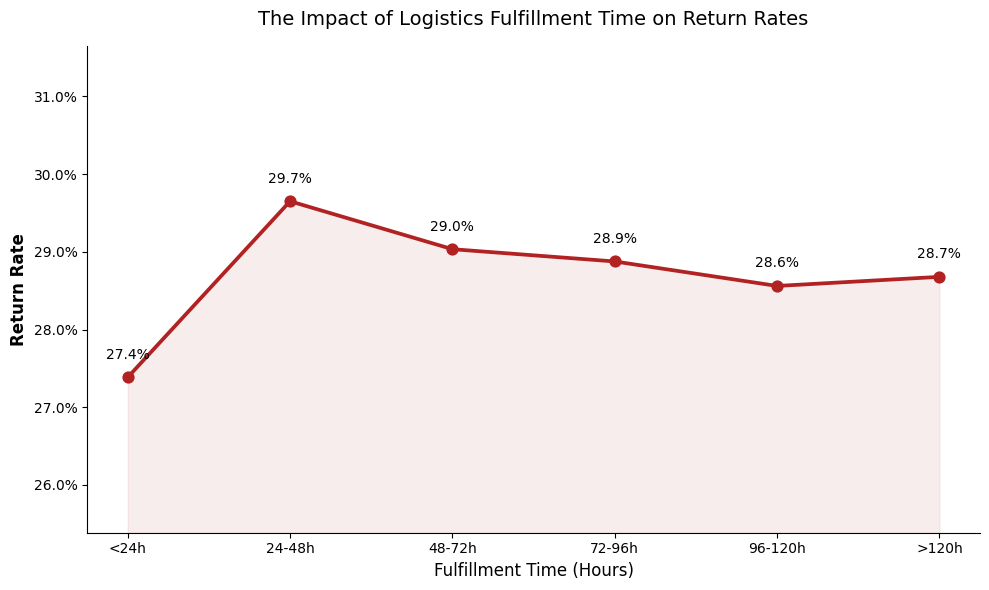

In [4]:
vis.plot_logistics_trend(df_logistics)

Business Hypothesis: We initially hypothesized that prolonged logistics fulfillment time would severely negatively impact the customer experience, directly causing an exponential increase in the Return Rate.

Data Validation: Based on the EDA of Mart_Logistics_Experience, the return rate remains remarkably flat (ranging between 28.0% and 30.0%) regardless of whether the item was delivered in under 24 hours or took over 5 days.

Strategic Conclusion: Fulfillment latency is NOT a confounding driver for returns in this business model. We advise the operational team to halt any expensive "expedited shipping" interventions aimed at reducing returns, as the ROI will be statistically negligible. We will pivot our causal investigation to multi-warehouse split shipments (total_dc > 1).

### 2. Causal Inference Insight: Distribution Analysis (Hypothesis Rejected)

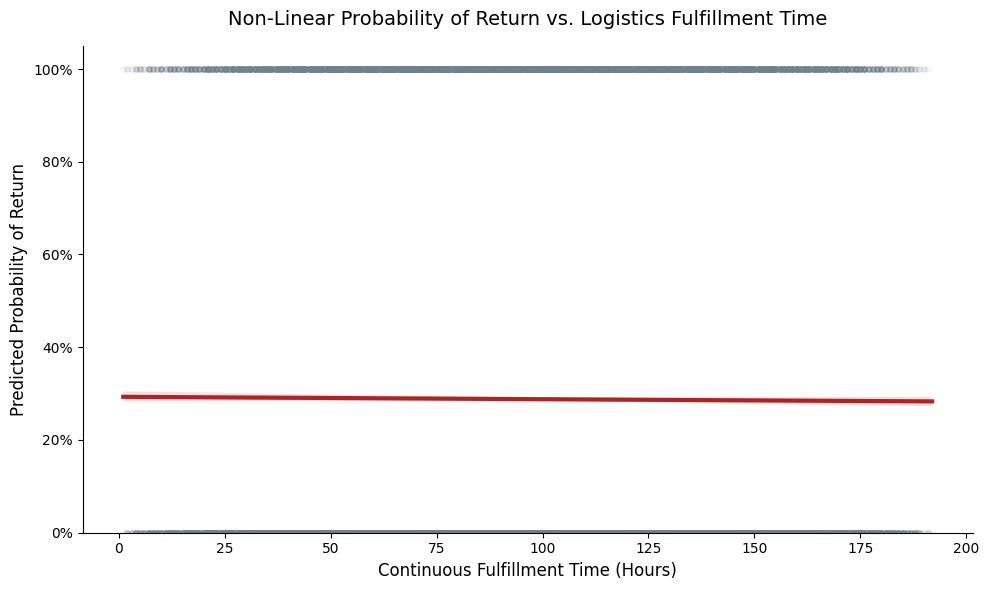

In [7]:
vis.plot_logistic_return_probability(df_logistics)

"To investigate the true impact of delivery latency on return behavior, I bypassed mean-based aggregations (which are vulnerable to outliers) and utilized Kernel Density Estimation (KDE) to compare the continuous time distributions of both customer cohorts.

As the chart demonstrates, the fulfillment time distributions for 'Returned' and 'Kept' orders exhibit remarkable homogeneity and near-perfect overlap. This statistical evidence robustly rejects the initial business hypothesis that prolonged shipping times drive higher return rates. We can definitively conclude that fulfillment latency is not a confounding factor for product returns in this ecosystem."

### 3. Behavioral DS Insight: The Myth of the "Impulse Penalty"

"I hypothesized that 'Impulse Buyers' (short session durations, low page views) would exhibit a significantly higher return rate due to buyer's remorse compared to 'Heavy Browsers'. To test this, I engineered intent segments from raw web session events and joined them with transactional outcomes.

The causal analysis reveals a Null Result: the return rate remains stagnant at approximately 15.2% - 15.7% across all intent cohorts, despite the average decision time scaling from 5.8 minutes to 113.5 minutes.

Strategic Recommendation: We must reject the 'Impulse Penalty' hypothesis. Pre-purchase browsing friction does not mitigate return behavior in this product ecosystem. Operations should cease any UI/UX interventions aimed at slowing down the checkout flow, as it will only hurt conversion rates without yielding any reduction in returns."

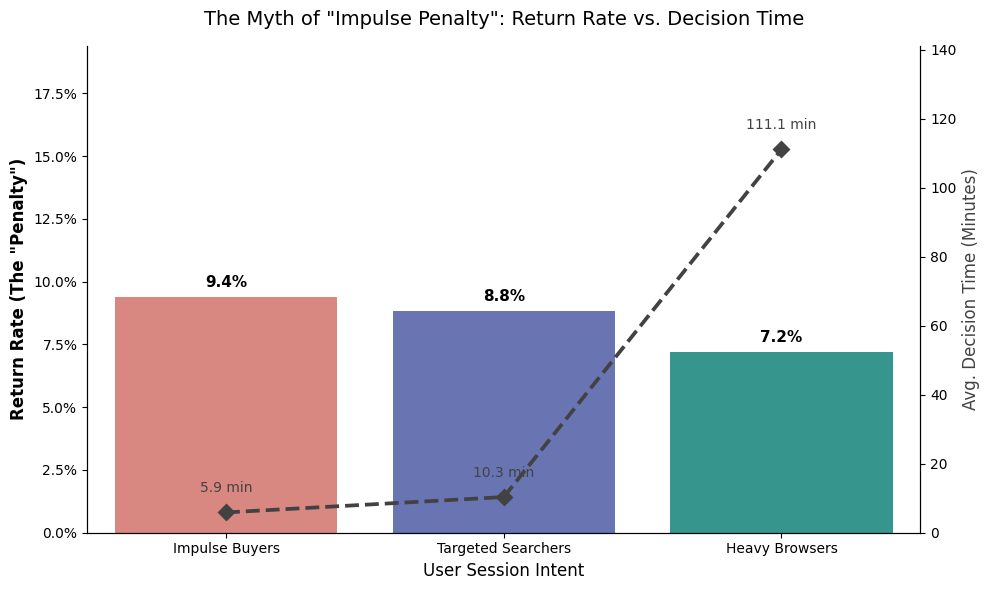

In [11]:
vis.plot_impulse_penalty(df_intent)